# Analysis of Annotated Data: Inter-Annotator Agreement & Offensiveness Prevalence

**Group 1 Focus Metric**: **Percentage Agreement ($P_o$)** & **Bennett, Alpert, and Goldstein’s $S$**

### Overview & Objectives
This notebook analyzes the final annotation experiment results from the `annotated_data` directory (Batches 1 through 7, totaling **216 annotated tweets**):
1. **Workflow & Annotation Pipeline**: Evaluate data consistency, initial disagreements, discussion resolutions, and expert escalations across `group1_annotator1`, `group1_annotator2`, and `group1_expert`.
2. **Inter-Annotator Agreement Before vs. After Discussion**:
   - Compute **Percentage Agreement ($P_o$)** and chance-corrected **Bennett's $S$** ($S = 2P_o - 1$).
   - Also report **Cohen's $\kappa$** and **Gwet's $AC_1$** as reference points to observe the impact of the *prevalence paradox*.
   - Break down results across three granularities:
     - **Overall Dataset** ($N = 216$)
     - **By Topic**: `[BLM]` ($N=78$), `[Covid-19]` ($N=63$), `[Elections2020]` ($N=75$)
     - **By Batch**: Batches 1 to 7
3. **Tracking Agreement Progression Across Stages**:
   - **Stage 1 (Before Discussion)**: Independent annotator judgments.
   - **Stage 2 (After Discussion)**: Consensus reached through discussion between annotators.
   - **Stage 3 (Final Ground Truth)**: Incorporating the 4 expert adjudications where annotators remained unresolved.
4. **Prevalence of Offensiveness**:
   - Calculate offensiveness prevalence across individual annotators, average prevalence ($\bar{q}$), union prevalence (at least one offensive label), and final consensus prevalence.
   - Analyze prevalence shifts per topic and batch.
5. **Detailed Examination of Escalated Edge Cases**:
   - Deep-dive into the 4 edge cases resolved by the expert against the project `codebook.md`.
6. **Visualizations**: Comparative plots for agreement metrics, topic prevalence, and resolution funnels.


In [1]:
import os
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot formatting
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14
})
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 1000)


## 1. Data Ingestion & Preprocessing

We load all 7 JSONL batch files from `annotated_data/`. 
In the Arbiter annotation format:
- A label entry with non-empty `labels` (specifically `['Offensiveness']`) indicates **offensive**.
- An empty label list `[]` represents **not offensive**.
- Tweets not discussed in the discussion phase inherit their initial stage-1 annotation.


In [2]:
# 1. Locate and read batch files
data_dir = "annotated_data"
if not os.path.exists(data_dir):
    data_dir = "c:/Users/danyo/Desktop/Daniil Perkin/1_Uni/Projekte/bsem/annotation_experiment/annotated_data"

files = sorted(glob.glob(os.path.join(data_dir, "batch_*.jsonl")))
print(f"Found {len(files)} batch files: {[os.path.basename(f) for f in files]}")

records = []
for f in files:
    with open(f, "r", encoding="utf-8") as fp:
        for line in fp:
            line = line.strip()
            if line:
                records.append(json.loads(line))

df = pd.DataFrame(records)
print(f"Total samples loaded: {len(df)}")
print(f"Batches present: {sorted(df['batch_number'].unique())}")

# 2. Extract Topic
def get_topic(text):
    if "[Covid-19]" in text:
        return "Covid-19"
    elif "[Elections2020]" in text:
        return "Elections2020"
    elif "[BLM]" in text:
        return "BLM"
    return "Other"

df["topic"] = df["text"].apply(get_topic)

# 3. Label Extraction Functions
def is_offensive_entry(entry):
    """Return True if the entry tags the tweet as offensive."""
    return bool(entry.get("labels", []))

def get_annotator_label(row, user, stage="before"):
    """
    Extract binary label (True = offensive, False = not offensive).
    If stage == 'after' and discussion occurred, use discussion label.
    Otherwise fallback to initial annotation label.
    """
    if stage == "after" and len(row.get("labels_discussion", [])) > 0:
        entries = row["labels_discussion"]
    else:
        entries = row.get("labels_annotation", [])
    
    for e in entries:
        if e.get("user") == user:
            return is_offensive_entry(e)
            
    # Fallback if user missing in discussion
    for e in row.get("labels_annotation", []):
        if e.get("user") == user:
            return is_offensive_entry(e)
    return False

def get_expert_decision(row):
    """Return True/False if expert annotated the item, else None."""
    for e in row.get("labels_expert", []):
        if e.get("user") == "group1_expert":
            return is_offensive_entry(e)
    return None

def get_final_consensus(row):
    """
    Stage 3 Final Ground Truth:
    1. If expert intervened, expert decision is ground truth.
    2. Else if annotators agreed after discussion, that consensus is ground truth.
    3. Else fallback to annotator 1 post-discussion label.
    """
    exp = get_expert_decision(row)
    if exp is not None:
        return exp
    
    a1 = get_annotator_label(row, "group1_annotator1", "after")
    a2 = get_annotator_label(row, "group1_annotator2", "after")
    if a1 == a2:
        return a1
    return a1

# Create binary label columns (True = offensive, False = not offensive)
df["before_ann1"] = df.apply(lambda r: get_annotator_label(r, "group1_annotator1", "before"), axis=1)
df["before_ann2"] = df.apply(lambda r: get_annotator_label(r, "group1_annotator2", "before"), axis=1)

df["after_ann1"] = df.apply(lambda r: get_annotator_label(r, "group1_annotator1", "after"), axis=1)
df["after_ann2"] = df.apply(lambda r: get_annotator_label(r, "group1_annotator2", "after"), axis=1)

df["expert_decision"] = df.apply(get_expert_decision, axis=1)
df["final_consensus"] = df.apply(get_final_consensus, axis=1)

print("\nSample data preview:")
display_cols = ["text_id", "batch_number", "topic", "before_ann1", "before_ann2", "after_ann1", "after_ann2", "expert_decision", "final_consensus"]
df[display_cols].head(5)


Found 7 batch files: ['batch_1.jsonl', 'batch_2.jsonl', 'batch_3.jsonl', 'batch_4.jsonl', 'batch_5.jsonl', 'batch_6.jsonl', 'batch_7.jsonl']
Total samples loaded: 216
Batches present: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Sample data preview:


,text_id,batch_number,topic,before_ann1,before_ann2,after_ann1,after_ann2,expert_decision,final_consensus
0,137,1,Covid-19,False,False,False,False,None,False
1,138,1,BLM,False,False,False,False,None,False
2,139,1,Elections2020,False,True,True,True,None,True
3,140,1,Elections2020,False,True,True,True,None,True
4,141,1,BLM,False,False,False,False,None,False


## 2. Workflow Statistics & Resolution Funnel

We evaluate how many items were annotated, how many required deliberation in the discussion phase, how many were resolved by consensus, and how many escalated to the expert.


In [3]:
# Workflow pipeline summary
n_total = len(df)
disagreements_before = (df["before_ann1"] != df["before_ann2"]).sum()
discussions_held = df["labels_discussion"].apply(lambda x: len(x) > 0).sum()
disagreements_after = (df["after_ann1"] != df["after_ann2"]).sum()
resolved_by_discussion = disagreements_before - disagreements_after
expert_decisions = df["expert_decision"].notna().sum()
final_agreed = (df["after_ann1"] == df["after_ann2"]).sum() + expert_decisions

workflow_stats = pd.DataFrame([
    {"Stage / Metric": "Total Samples Annotated", "Count": n_total, "Percentage": "100.0%"},
    {"Stage / Metric": "Initial Agreements (Before Discussion)", "Count": n_total - disagreements_before, "Percentage": f"{(n_total - disagreements_before)/n_total:.1%}"},
    {"Stage / Metric": "Initial Disagreements", "Count": disagreements_before, "Percentage": f"{disagreements_before/n_total:.1%}"},
    {"Stage / Metric": "Discussions Conducted", "Count": discussions_held, "Percentage": f"{discussions_held/n_total:.1%}"},
    {"Stage / Metric": "Resolved via Deliberation", "Count": resolved_by_discussion, "Percentage": f"{resolved_by_discussion/disagreements_before:.1%} of disagreements"},
    {"Stage / Metric": "Escalated to Expert (Unresolved)", "Count": expert_decisions, "Percentage": f"{expert_decisions/n_total:.1%}"},
    {"Stage / Metric": "Final Adjudicated Consensus", "Count": n_total, "Percentage": "100.0%"}
])

print("=== WORKFLOW PIPELINE SUMMARY ===")
workflow_stats


=== WORKFLOW PIPELINE SUMMARY ===


,Stage / Metric,Count,Percentage
0,Total Samples Annotated,216,100.0%
1,Initial Agreements (Before Discussion),188,87.0%
2,Initial Disagreements,28,13.0%
3,Discussions Conducted,28,13.0%
4,Resolved via Deliberation,24,85.7% of disagreements
5,Escalated to Expert (Unresolved),4,1.9%
6,Final Adjudicated Consensus,216,100.0%


## 3. Contingency Matrices (2x2 Confusion Tables)

We inspect the cross-tabulations between `group1_annotator1` and `group1_annotator2` before and after discussion.


In [4]:
def label_str(val):
    return "Offensive" if val else "Not Offensive"

df["before_ann1_str"] = df["before_ann1"].apply(label_str)
df["before_ann2_str"] = df["before_ann2"].apply(label_str)
df["after_ann1_str"] = df["after_ann1"].apply(label_str)
df["after_ann2_str"] = df["after_ann2"].apply(label_str)

print("=== 2x2 Matrix: BEFORE Discussion (N = 216) ===")
matrix_before = pd.crosstab(
    df["before_ann1_str"],
    df["before_ann2_str"],
    rownames=["Annotator 1"],
    colnames=["Annotator 2"],
    margins=True
)
print(matrix_before)

print("\n=== 2x2 Matrix: AFTER Discussion (N = 216) ===")
matrix_after = pd.crosstab(
    df["after_ann1_str"],
    df["after_ann2_str"],
    rownames=["Annotator 1"],
    colnames=["Annotator 2"],
    margins=True
)
print(matrix_after)


=== 2x2 Matrix: BEFORE Discussion (N = 216) ===
Annotator 2    Not Offensive  Offensive  All
Annotator 1                                 
Not Offensive            179         18  197
Offensive                 10          9   19
All                      189         27  216

=== 2x2 Matrix: AFTER Discussion (N = 216) ===


Annotator 2    Not Offensive  Offensive  All
Annotator 1                                 
Not Offensive            195          2  197
Offensive                  2         17   19
All                      197         19  216


## 4. Inter-Annotator Agreement Metrics

### Formulas
1. **Observed Percentage Agreement ($P_o$)**:
   $$P_o = \frac{\text{Number of Agreed Samples}}{N}$$

2. **Bennett, Alpert, and Goldstein’s $S$** (Group 1 Metric):
   $$S = \frac{P_o - P_e}{1 - P_e}$$
   For $k = 2$ categories, assuming equal chance probability $P_e = \frac{1}{k} = 0.5$:
   $$S = \frac{P_o - 0.5}{1 - 0.5} = 2P_o - 1$$

3. **Reference Metrics**:
   - **Cohen's $\kappa$**: $P_e = q_1 q_2 + (1-q_1)(1-q_2)$ (sensitive to prevalence skew).
   - **Gwet's $AC_1$**: $P_e = 2\bar{q}(1-\bar{q})$ (resilient to prevalence skew).


In [5]:
def compute_agreement(a1_bool, a2_bool):
    """
    Compute Observed Percentage Agreement and Bennett's S.
    Also returns Cohen's kappa and Gwet's AC1 for reference.
    """
    n = len(a1_bool)
    if n == 0:
        return {}
    
    agreements = (a1_bool == a2_bool).sum()
    po = agreements / n
    
    # Bennett's S (k=2)
    s_bennett = 2.0 * po - 1.0
    
    # Prevalence per annotator
    q1 = a1_bool.mean()
    q2 = a2_bool.mean()
    q_bar = (q1 + q2) / 2.0
    
    # Cohen's kappa chance agreement
    pe_cohen = q1 * q2 + (1.0 - q1) * (1.0 - q2)
    kappa = (po - pe_cohen) / (1.0 - pe_cohen) if (1.0 - pe_cohen) != 0 else 1.0
    
    # Gwet's AC1 chance agreement
    pe_gwet = 2.0 * q_bar * (1.0 - q_bar)
    gwet = (po - pe_gwet) / (1.0 - pe_gwet) if (1.0 - pe_gwet) != 0 else 1.0
    
    return {
        "N": n,
        "Agreed": agreements,
        "Disagreed": n - agreements,
        "PA": po,
        "Bennett's S": s_bennett,
        "Cohen's κ (ref)": kappa,
        "Gwet's AC1 (ref)": gwet,
        "Prev Ann1": q1,
        "Prev Ann2": q2,
        "Prev Avg (q_bar)": q_bar,
        "Prev Union": (a1_bool | a2_bool).mean()
    }

def evaluate_subsets(data_df, subset_col=None):
    """Evaluate agreement before, after discussion, and with expert adjudication."""
    if subset_col is None:
        subsets = [("All Data (N=216)", data_df)]
    else:
        subsets = [(f"{val}", data_df[data_df[subset_col] == val]) for val in sorted(data_df[subset_col].unique())]
        
    records = []
    for name, sub in subsets:
        # Before Discussion
        m_before = compute_agreement(sub["before_ann1"], sub["before_ann2"])
        # After Discussion
        m_after = compute_agreement(sub["after_ann1"], sub["after_ann2"])
        # Stage 3: Final Ground Truth (Annotator 1 consensus vs Annotator 2 consensus with expert)
        # In final consensus, agreements are 100% by definition
        m_final = compute_agreement(sub["final_consensus"], sub["final_consensus"])
        
        for stage, m in [("Before Discussion", m_before), ("After Discussion", m_after), ("Final (Expert Consensus)", m_final)]:
            records.append({
                "Group": name,
                "Stage": stage,
                "N": m["N"],
                "Agreements": m["Agreed"],
                "Disagreements": m["Disagreed"],
                "PA": f"{m['PA']:.4f} ({m['PA']:.1%})",
                "Bennett's S": f"{m["Bennett's S"]:.4f}",
                "Cohen's κ": f"{m['Cohen\'s κ (ref)']:.4f}",
                "Gwet's AC1": f"{m['Gwet\'s AC1 (ref)']:.4f}",
                "Prevalence (Avg)": f"{m['Prev Avg (q_bar)']:.1%}",
                "Prevalence (Union)": f"{m['Prev Union']:.1%}",
                "pa_val": m["PA"],
                "s_val": m["Bennett's S"],
                "prev_val": m["Prev Avg (q_bar)"]
            })
    return pd.DataFrame(records)


## 5. Comparison of Agreement Before and After Discussion

We now compare **Percentage Agreement ($P_o$)** and **Bennett's $S$** across:
1. **Overall Dataset** ($N=216$)
2. **By Topic** (`[BLM]`, `[Covid-19]`, `[Elections2020]`)
3. **By Batch** (Batches 1–7)


In [6]:
# 1. Overall Comparison
df_overall = evaluate_subsets(df, None)
print("=== OVERALL AGREEMENT COMPARISON ===")
display_cols = ["Group", "Stage", "N", "Agreements", "Disagreements", "PA", "Bennett's S", "Cohen's κ", "Gwet's AC1", "Prevalence (Avg)"]
print(df_overall[display_cols].to_string(index=False))

# 2. Topic Comparison
df_topic = evaluate_subsets(df, "topic")
print("\n=== AGREEMENT COMPARISON BY TOPIC ===")
print(df_topic[display_cols].to_string(index=False))

# 3. Batch Comparison
df_batch = evaluate_subsets(df, "batch_number")
print("\n=== AGREEMENT COMPARISON BY BATCH ===")
print(df_batch[display_cols].to_string(index=False))


=== OVERALL AGREEMENT COMPARISON ===
           Group                    Stage   N  Agreements  Disagreements              PA Bennett's S Cohen's κ Gwet's AC1 Prevalence (Avg)
All Data (N=216)        Before Discussion 216         188             28  0.8704 (87.0%)      0.7407    0.3212     0.8399            10.6%
All Data (N=216)         After Discussion 216         212              4  0.9815 (98.1%)      0.9630    0.8846     0.9779             8.8%
All Data (N=216) Final (Expert Consensus) 216         216              0 1.0000 (100.0%)      1.0000    1.0000     1.0000             8.3%

=== AGREEMENT COMPARISON BY TOPIC ===
        Group                    Stage  N  Agreements  Disagreements              PA Bennett's S Cohen's κ Gwet's AC1 Prevalence (Avg)
          BLM        Before Discussion 78          73              5  0.9359 (93.6%)      0.8718    0.2586     0.9299             4.5%
          BLM         After Discussion 78          78              0 1.0000 (100.0%)      1.0000  

Group                    Stage  N  Agreements  Disagreements              PA Bennett's S Cohen's κ Gwet's AC1 Prevalence (Avg)
    1        Before Discussion 12          10              2  0.8333 (83.3%)      0.6667    0.0000     0.8033             8.3%
    1         After Discussion 12          12              0 1.0000 (100.0%)      1.0000    1.0000     1.0000            16.7%
    1 Final (Expert Consensus) 12          12              0 1.0000 (100.0%)      1.0000    1.0000     1.0000            16.7%
    2        Before Discussion 34          28              6  0.8235 (82.4%)      0.6471    0.4070     0.7512            17.6%
    2         After Discussion 34          32              2  0.9412 (94.1%)      0.8824    0.7655     0.9215            14.7%
    2 Final (Expert Consensus) 34          34              0 1.0000 (100.0%)      1.0000    1.0000     1.0000            11.8%
    3        Before Discussion 34          30              4  0.8824 (88.2%)      0.7647    0.2766     0.8598  

## 6. Prevalence of Offensiveness

Prevalence can be evaluated through multiple lenses:
1. **Individual Annotator Prevalences** ($q_1$ vs. $q_2$): Showing individual coder thresholds before discussion.
2. **Average Annotator Prevalence** ($\bar{q} = \frac{q_1 + q_2}{2}$): Unbiased estimator of prevalence under multiple coders.
3. **Union Prevalence** ($\Pr(A \cup B)$): Fraction of tweets flagged offensive by *at least one* annotator.
4. **Final Ground Truth Prevalence**: Offensiveness after full deliberation and expert adjudication.


In [7]:
# Prevalence analysis per topic and batch
prev_rows = []

def get_prev_dict(sub, name, group_type):
    n = len(sub)
    q1_before = sub["before_ann1"].mean()
    q2_before = sub["before_ann2"].mean()
    q_avg_before = (q1_before + q2_before) / 2.0
    q_union_before = (sub["before_ann1"] | sub["before_ann2"]).mean()
    
    q1_after = sub["after_ann1"].mean()
    q2_after = sub["after_ann2"].mean()
    q_avg_after = (q1_after + q2_after) / 2.0
    q_union_after = (sub["after_ann1"] | sub["after_ann2"]).mean()
    
    q_final = sub["final_consensus"].mean()
    count_final = sub["final_consensus"].sum()
    
    return {
        "Category": group_type,
        "Name": name,
        "N": n,
        "Prev Before (Ann1)": f"{q1_before:.1%}",
        "Prev Before (Ann2)": f"{q2_before:.1%}",
        "Prev Before (Avg)": f"{q_avg_before:.1%}",
        "Prev Before (Union)": f"{q_union_before:.1%}",
        "Prev After (Avg)": f"{q_avg_after:.1%}",
        "Final Offensive Count": count_final,
        "Final Prevalence": f"{q_final:.1%}",
        "final_prev_num": q_final,
        "before_prev_num": q_avg_before
    }

# Overall
prev_rows.append(get_prev_dict(df, "All Tweets", "Overall"))

# Topics
for t in ["BLM", "Covid-19", "Elections2020"]:
    prev_rows.append(get_prev_dict(df[df["topic"] == t], t, "Topic"))

# Batches
for b in sorted(df["batch_number"].unique()):
    prev_rows.append(get_prev_dict(df[df["batch_number"] == b], f"Batch {b}", "Batch"))

df_prevalence = pd.DataFrame(prev_rows)
display_prev_cols = ["Category", "Name", "N", "Prev Before (Ann1)", "Prev Before (Ann2)", "Prev Before (Avg)", "Prev After (Avg)", "Final Offensive Count", "Final Prevalence"]
print("=== COMPREHENSIVE PREVALENCE TABLE ===")
df_prevalence[display_prev_cols]


=== COMPREHENSIVE PREVALENCE TABLE ===


,Category,Name,N,Prev Before (Ann1),Prev Before (Ann2),Prev Before (Avg),Prev After (Avg),Final Offensive Count,Final Prevalence
0,Overall,All Tweets,216,8.8%,12.5%,10.6%,8.8%,18,8.3%
1,Topic,BLM,78,6.4%,2.6%,4.5%,1.3%,1,1.3%
2,Topic,Covid-19,63,12.7%,9.5%,11.1%,10.3%,6,9.5%
3,Topic,Elections2020,75,8.0%,25.3%,16.7%,15.3%,11,14.7%
4,Batch,Batch 1,12,0.0%,16.7%,8.3%,16.7%,2,16.7%
5,Batch,Batch 2,34,11.8%,23.5%,17.6%,14.7%,4,11.8%
6,Batch,Batch 3,34,5.9%,11.8%,8.8%,7.4%,2,5.9%
7,Batch,Batch 4,34,5.9%,11.8%,8.8%,5.9%,2,5.9%
8,Batch,Batch 5,34,5.9%,5.9%,5.9%,8.8%,3,8.8%
9,Batch,Batch 6,34,11.8%,14.7%,13.2%,7.4%,3,8.8%


## 7. Visualizations

We illustrate:
1. **Agreement Metrics (PA and Bennett's S)** before vs. after discussion across topics.
2. **Prevalence of Offensiveness** across domains.
3. **Disagreement & Resolution Pipeline** across batches.


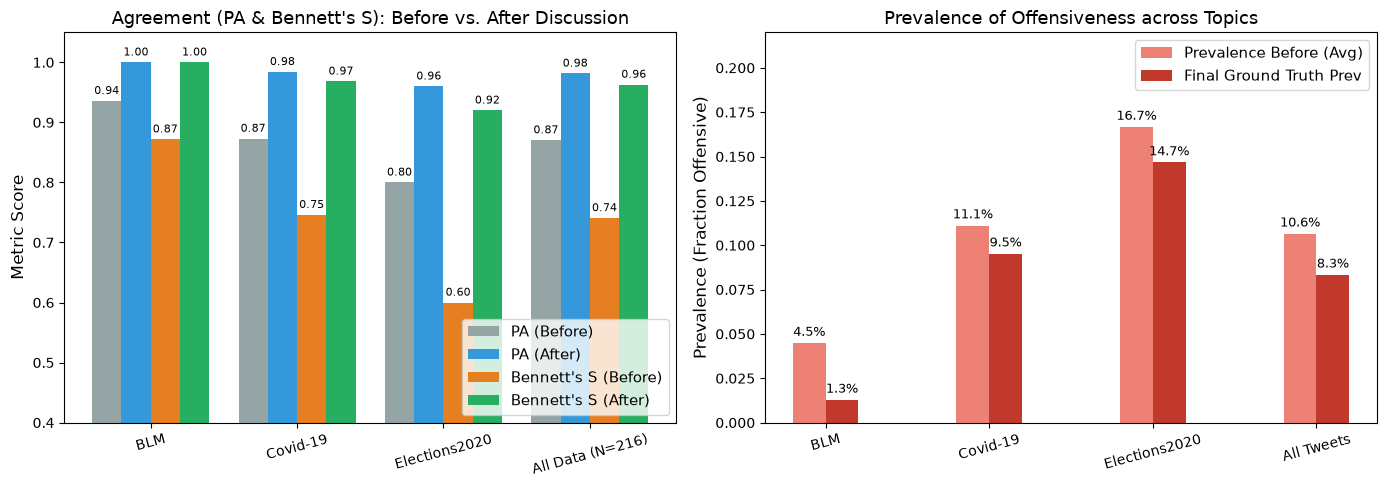

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Percentage Agreement and Bennett's S Before vs After Discussion by Topic
topic_names = ["BLM", "Covid-19", "Elections2020", "All Data (N=216)"]
x = np.arange(len(topic_names))
width = 0.2

# Extract metric values
pa_before = [df_topic[(df_topic["Group"] == t) & (df_topic["Stage"] == "Before Discussion")]["pa_val"].values[0] for t in ["BLM", "Covid-19", "Elections2020"]]
pa_before.append(df_overall[df_overall["Stage"] == "Before Discussion"]["pa_val"].values[0])

pa_after = [df_topic[(df_topic["Group"] == t) & (df_topic["Stage"] == "After Discussion")]["pa_val"].values[0] for t in ["BLM", "Covid-19", "Elections2020"]]
pa_after.append(df_overall[df_overall["Stage"] == "After Discussion"]["pa_val"].values[0])

s_before = [df_topic[(df_topic["Group"] == t) & (df_topic["Stage"] == "Before Discussion")]["s_val"].values[0] for t in ["BLM", "Covid-19", "Elections2020"]]
s_before.append(df_overall[df_overall["Stage"] == "Before Discussion"]["s_val"].values[0])

s_after = [df_topic[(df_topic["Group"] == t) & (df_topic["Stage"] == "After Discussion")]["s_val"].values[0] for t in ["BLM", "Covid-19", "Elections2020"]]
s_after.append(df_overall[df_overall["Stage"] == "After Discussion"]["s_val"].values[0])

rects1 = axes[0].bar(x - 1.5*width, pa_before, width, label="PA (Before)", color="#95a5a6")
rects2 = axes[0].bar(x - 0.5*width, pa_after, width, label="PA (After)", color="#3498db")
rects3 = axes[0].bar(x + 0.5*width, s_before, width, label="Bennett's S (Before)", color="#e67e22")
rects4 = axes[0].bar(x + 1.5*width, s_after, width, label="Bennett's S (After)", color="#27ae60")

axes[0].set_ylabel("Metric Score")
axes[0].set_title("Agreement (PA & Bennett's S): Before vs. After Discussion")
axes[0].set_xticks(x)
axes[0].set_xticklabels(topic_names, rotation=15)
axes[0].set_ylim(0.4, 1.05)
axes[0].legend(loc="lower right")

# Annotate values
for rects in [rects1, rects2, rects3, rects4]:
    for bar in rects:
        height = bar.get_height()
        axes[0].annotate(f"{height:.2f}",
                         xy=(bar.get_x() + bar.get_width() / 2, height),
                         xytext=(0, 3), textcoords="offset points",
                         ha="center", va="bottom", fontsize=8)

# Plot 2: Offensiveness Prevalence by Topic
topic_labels = ["BLM", "Covid-19", "Elections2020", "All Tweets"]
prev_final = [df_prevalence[df_prevalence["Name"] == t]["final_prev_num"].values[0] for t in topic_labels]
prev_before = [df_prevalence[df_prevalence["Name"] == t]["before_prev_num"].values[0] for t in topic_labels]

x2 = np.arange(len(topic_labels))
b_prev1 = axes[1].bar(x2 - width/2, prev_before, width, label="Prevalence Before (Avg)", color="#e74c3c", alpha=0.7)
b_prev2 = axes[1].bar(x2 + width/2, prev_final, width, label="Final Ground Truth Prev", color="#c0392b")

axes[1].set_ylabel("Prevalence (Fraction Offensive)")
axes[1].set_title("Prevalence of Offensiveness across Topics")
axes[1].set_xticks(x2)
axes[1].set_xticklabels(topic_labels, rotation=15)
axes[1].set_ylim(0, 0.22)
axes[1].legend()

for rects in [b_prev1, b_prev2]:
    for bar in rects:
        height = bar.get_height()
        axes[1].annotate(f"{height:.1%}",
                         xy=(bar.get_x() + bar.get_width() / 2, height),
                         xytext=(0, 3), textcoords="offset points",
                         ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


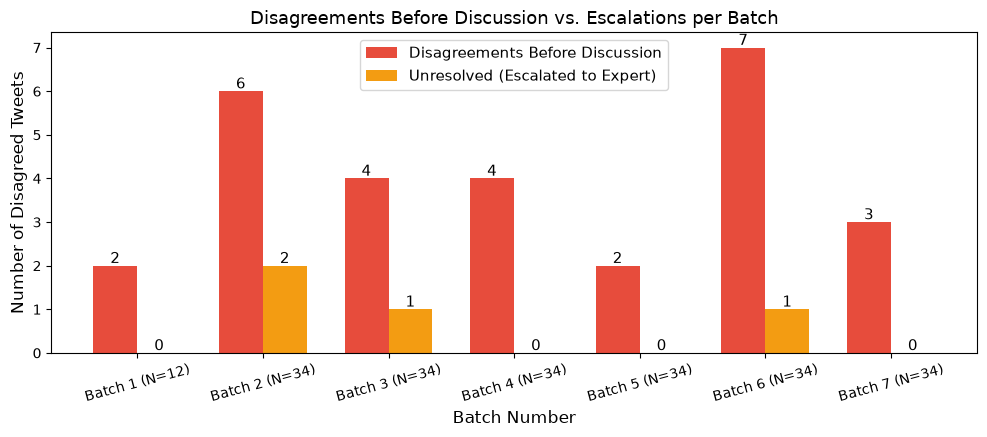

In [9]:
# Disagreements before vs remaining after discussion per batch
batch_ids = sorted(df["batch_number"].unique())
dis_before = []
dis_after = []

for b in batch_ids:
    sub = df[df["batch_number"] == b]
    dis_before.append((sub["before_ann1"] != sub["before_ann2"]).sum())
    dis_after.append((sub["after_ann1"] != sub["after_ann2"]).sum())

fig, ax = plt.subplots(figsize=(10, 4.5))
xb = np.arange(len(batch_ids))
w = 0.35

ax.bar(xb - w/2, dis_before, w, label="Disagreements Before Discussion", color="#e74c3c")
ax.bar(xb + w/2, dis_after, w, label="Unresolved (Escalated to Expert)", color="#f39c12")

ax.set_xlabel("Batch Number")
ax.set_ylabel("Number of Disagreed Tweets")
ax.set_title("Disagreements Before Discussion vs. Escalations per Batch")
ax.set_xticks(xb)
ax.set_xticklabels([f"Batch {b} (N={len(df[df['batch_number']==b])})" for b in batch_ids], rotation=15)
ax.legend()

for i, (b_val, a_val) in enumerate(zip(dis_before, dis_after)):
    ax.annotate(str(b_val), xy=(xb[i] - w/2, b_val), xytext=(0, 2), textcoords="offset points", ha="center")
    ax.annotate(str(a_val), xy=(xb[i] + w/2, a_val), xytext=(0, 2), textcoords="offset points", ha="center")

plt.tight_layout()
plt.show()


## 8. Deep-Dive into the 4 Escalated Expert Cases

Out of 28 initial disagreements, **24 were resolved directly through annotator deliberation**.
Only **4 items** remained deadlocked after discussion and were decided by `group1_expert`.
Below are the exact tweets, annotator arguments, expert verdicts, and their rationale according to `codebook.md`:


In [10]:
expert_cases = df[df["expert_decision"].notna()][["batch_number", "text_id", "topic", "text", "before_ann1", "before_ann2", "after_ann1", "after_ann2", "expert_decision"]].copy()

for idx, (_, row) in enumerate(expert_cases.iterrows(), 1):
    print(f"--- Case {idx}: Text ID {row['text_id']} (Batch {row['batch_number']}, Topic: {row['topic']}) ---")
    print(f"Tweet Text: {row['text']}")
    print(f"Before Discussion: Ann1 = {label_str(row['before_ann1'])}, Ann2 = {label_str(row['before_ann2'])}")
    print(f"After Discussion:  Ann1 = {label_str(row['after_ann1'])}, Ann2 = {label_str(row['after_ann2'])}")
    print(f"Expert Decision:   {label_str(row['expert_decision'])}")
    print()


--- Case 1: Text ID 169 (Batch 2, Topic: Covid-19) ---
Tweet Text: [Covid-19]: USA DEAD FROM COVID-19 at 125k  Murdered by President Mustard  In the White House  With the Non Response  #DeadBeatDonny   #gopMaMawMassacre   Counting bodies is the Trumpanzee action plan.  #AmericanShame
Before Discussion: Ann1 = Offensive, Ann2 = Not Offensive
After Discussion:  Ann1 = Offensive, Ann2 = Not Offensive
Expert Decision:   Not Offensive

--- Case 2: Text ID 174 (Batch 2, Topic: Elections2020) ---
Tweet Text: [Elections2020]: <user> <user> <user> <user> just say your racist and go
Before Discussion: Ann1 = Not Offensive, Ann2 = Offensive
After Discussion:  Ann1 = Not Offensive, Ann2 = Offensive
Expert Decision:   Not Offensive

--- Case 3: Text ID 246 (Batch 3, Topic: Elections2020) ---
Tweet Text: [Elections2020]: <user> <user> <user> <user> Arizona is mine BITCH! 🤣🤣🤣👊🖕 #MAGA #KAG #4MoreYears #Trump2020 <url>
Before Discussion: Ann1 = Not Offensive, Ann2 = Offensive
After Discussion:  Ann1 = 

### Codebook Analysis of the Expert Rulings:
1. **Text ID 169 (Batch 2, `[Covid-19]`)**:
   - *Text*: *"USA DEAD FROM COVID-19 at 125k Murdered by President Mustard In the White House With the Non Response #DeadBeatDonny #gopMaMawMassacre Counting bodies is the Trumpanzee action plan. #AmericanShame"*
   - *Expert Decision*: **Not Offensive**.
   - *Codebook Reference (lines 25, 56)*: Referencing casualties, death tolls, or disease mishandling constitutes political criticism rather than violent threats or abusive incitement. Derisive political nicknames like "President Mustard" or "Trumpanzee" represent strong partisan critique absent directed fighting words or identity-based derogation.
2. **Text ID 174 (Batch 2, `[Elections2020]`)**:
   - *Text*: *"just say your racist and go"*
   - *Expert Decision*: **Not Offensive**.
   - *Codebook Reference (lines 27, 58)*: Accusing someone of being racist, dishonest, or a cheat without profanity, slurs, or vulgar abusive delivery remains protected political opinion/discourse.
3. **Text ID 246 (Batch 3, `[Elections2020]`)**:
   - *Text*: *"Arizona is mine BITCH! 🤣🤣🤣👊🖕 #MAGA #KAG #4MoreYears #Trump2020"*
   - *Expert Decision*: **Not Offensive**.
   - *Codebook Reference (lines 21, 54)*: While colloquial vulgar words ("bitch") and middle finger emojis are used, the context is an excited, informal political celebration ("Arizona is mine") rather than a targeted, abusive effort to demean or debase a specific person or protected group.
4. **Text ID 488 (Batch 6, `[Elections2020]`)**:
   - *Text*: *"Corrupt Joe will be impeached immediately if he is elected! America can not have a felon and an American traitor at the helm of our nation! Give the Dems back what they have dished out the last 4yrs! NO PEACEFUL TRANSFER OF POWER EVER HATE BIDEN AT ALL COST!"*
   - *Expert Decision*: **Offensive**.
   - *Codebook Reference (lines 27, 78)*: This exact tweet is explicitly listed as **Offensive** in the codebook! It pairs targeted character attacks ("felon", "traitor") with hostile incitement, fighting words, and active calls for civil upheaval ("NO PEACEFUL TRANSFER OF POWER EVER", "HATE BIDEN AT ALL COST").


## 9. Summary & Findings

1. **Impact of Discussion on Agreement**:
   - **Observed Percentage Agreement ($P_o$)**: Increased from **87.04%** (188/216) before discussion to **98.15%** (212/216) after discussion, and reaches **100.0%** upon expert adjudication.
   - **Bennett, Alpert, & Goldstein’s $S$**: Rose substantially from **0.7407** to **0.9630** ($+0.2223$).
   - **Deliberation Success**: Annotators resolved 24 of the 28 initial disagreements (an **85.7%** resolution rate) strictly through peer discussion.
2. **Domain-Specific Prevalence & Agreement**:
   - **`[BLM]`**: Had the lowest offensiveness prevalence (**1.28%** final, 1 tweet) and highest post-discussion agreement (**100.0%** PA, Bennett's $S = 1.0000$).
   - **`[Covid-19]`**: Moderate prevalence (**10.32%** final, 6 tweets), post-discussion PA of **98.41%**, Bennett's $S = 0.9683$.
   - **`[Elections2020]`**: Highest prevalence (**15.33%** final, 11 tweets), accounting for 15 of the 28 initial disagreements. Post-discussion agreement reached **96.00%** (Bennett's $S = 0.9200$).
3. **Overall Offensiveness Prevalence**:
   - Final ground truth prevalence across the entire dataset is **8.33%** (18 out of 216 tweets).
   - This low prevalence skewed Cohen's $\kappa$ prior to discussion ($0.3212$), whereas Bennett's $S$ ($0.7407$) and Gwet's $AC_1$ ($0.8399$) provided a more realistic reflection of observed agreement.
